**Import libraries**

In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras.layers import *
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import mean_absolute_error as mae

def mape(y_true, y_pred):
    # Convert to numpy arrays if they are not already
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Avoid division by zero (for cases where actual value is zero)
    # Replace zeroes in the true values with a small number (e.g., 1e-10)
    y_true = np.where(y_true == 0, 1e-10, y_true)

    # Calculate MAPE
    error = np.abs((y_true - y_pred) / y_true) * 100
    return np.mean(error)

In [ ]:
def smape(y_true, y_pred):
    numerator = np.abs(y_pred - y_true)
    denominator = (np.abs(y_pred) + np.abs(y_true)) / 2
    smape_val = np.mean(numerator / np.where(denominator == 0, 1, denominator)) * 100
    return smape_val


## **Data Preprocessing**

Read the data

In [ ]:
train_path = "/content/train_data.xlsx"
val_path = "/content/validation_data.xlsx"

df_train = pd.read_excel(train_path)
df_val = pd.read_excel(val_path)

In [ ]:
df_train = df_train.set_index('Date') #set index to 'Date'
df_val = df_val.set_index('Date')

Function to categorize into different time frames

In [ ]:
#time series features
def create_time_series_features(df, date_col='timestamp'):
    """
    Creates time series features based on a datetime column (not index).

    Parameters:
        df (pd.DataFrame): The input DataFrame.
        date_col (str): The name of the datetime column.

    Returns:
        pd.DataFrame: DataFrame with additional time-based features.
    """
    df = df.copy()

    # Ensure it's datetime
    df[date_col] = pd.to_datetime(df[date_col])

    df['hour'] = df[date_col].dt.hour
    df['month'] = df[date_col].dt.month
    df['year'] = df[date_col].dt.year
    df['dayofweek'] = df[date_col].dt.dayofweek #starts on monday
    df['dayofyear'] = df[date_col].dt.dayofyear
    df['quarter'] = df[date_col].dt.quarter
    df['dayofmonth'] = df[date_col].dt.day
    df['weekofyear'] = df[date_col].dt.isocalendar().week
    df['date_offset'] = (df[date_col].dt.month * 100 + df[date_col].dt.day - 320) % 1300
    df['season'] = pd.cut(df['date_offset'], [-1, 300, 602, 900, 1301],
                          labels=[0, 1,2,3])
    #since we observe periodic patterns for time of day and month of year, we add new features
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

    df['week_sin'] = np.sin(2 * np.pi * df['dayofweek'] / 7)
    df['week_cos'] = np.cos(2 * np.pi * df['dayofweek'] / 7)

    return df


Create a new melted Dataframe having indexof timestamps of 15-min-interval

In [ ]:
df_train.columns = pd.date_range(start='00:00', periods=96, freq='15min').time #transform column index to time
df_reset = df_train.reset_index() #before melting gotta reset index
df_long = df_reset.melt(id_vars='Date', var_name= 'Time', value_name='Power Usage')
df_long['timestamp'] = pd.to_datetime(df_long['Date'].astype(str) + ' ' + df_long['Time'].astype(str))
df_long = create_time_series_features(df_long)
df_long= df_long.set_index('timestamp')
df_long.sort_index(inplace=True)
df_long = df_long.drop(columns = ['Date','Time'])


#handling missing values using interpolate
df_filled = df_long.copy()
df_filled['Power Usage'] = df_filled['Power Usage'].interpolate(method='linear')

df_filled.head()

,Power Usage,hour,month,year,dayofweek,dayofyear,quarter,dayofmonth,weekofyear,date_offset,season,hour_sin,hour_cos,month_sin,month_cos,week_sin,week_cos
timestamp,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,0.5224,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521
2022-01-01 00:15:00,0.5170,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521
2022-01-01 00:30:00,0.4889,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521
2022-01-01 00:45:00,0.5746,0,1,2022,5,1,1,1,52,1081,3,0.000000,1.000000,0.5,0.866025,-0.974928,-0.222521
2022-01-01 01:00:00,0.5187,1,1,2022,5,1,1,1,52,1081,3,0.258819,0.965926,0.5,0.866025,-0.974928,-0.222521


In [ ]:
df_val.columns = pd.date_range(start='00:00', periods=96, freq='15min').time #transform column index to time
df_reset_val = df_val.reset_index() #before melting gotta reset index
df_val_long = df_reset_val.melt(id_vars='Date', var_name= 'Time', value_name='Power Usage')
df_val_long['timestamp'] = pd.to_datetime(df_val_long['Date'].astype(str) + ' ' + df_val_long['Time'].astype(str))
df_val_long = create_time_series_features(df_val_long)
df_val_long= df_val_long.set_index('timestamp')
df_val_long.sort_index(inplace=True)
df_val_long = df_val_long.drop(columns = ['Date','Time'])

#handling missing values using interpolate
df_val_filled = df_val_long.copy()
df_val_filled['Power Usage'] = df_val_filled['Power Usage'].interpolate(method='linear')

df_val_filled.head()

,Power Usage,hour,month,year,dayofweek,dayofyear,quarter,dayofmonth,weekofyear,date_offset,season,hour_sin,hour_cos,month_sin,month_cos,week_sin,week_cos
timestamp,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,0.1367,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0
2024-01-01 00:15:00,0.2140,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0
2024-01-01 00:30:00,0.1263,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0
2024-01-01 00:45:00,0.1227,0,1,2024,0,1,1,1,1,1081,3,0.000000,1.000000,0.5,0.866025,0.0,1.0
2024-01-01 01:00:00,0.1743,1,1,2024,0,1,1,1,1,1081,3,0.258819,0.965926,0.5,0.866025,0.0,1.0


## **Plots**

### Overview of data distribution over time period of 2 years. (2022-2023)

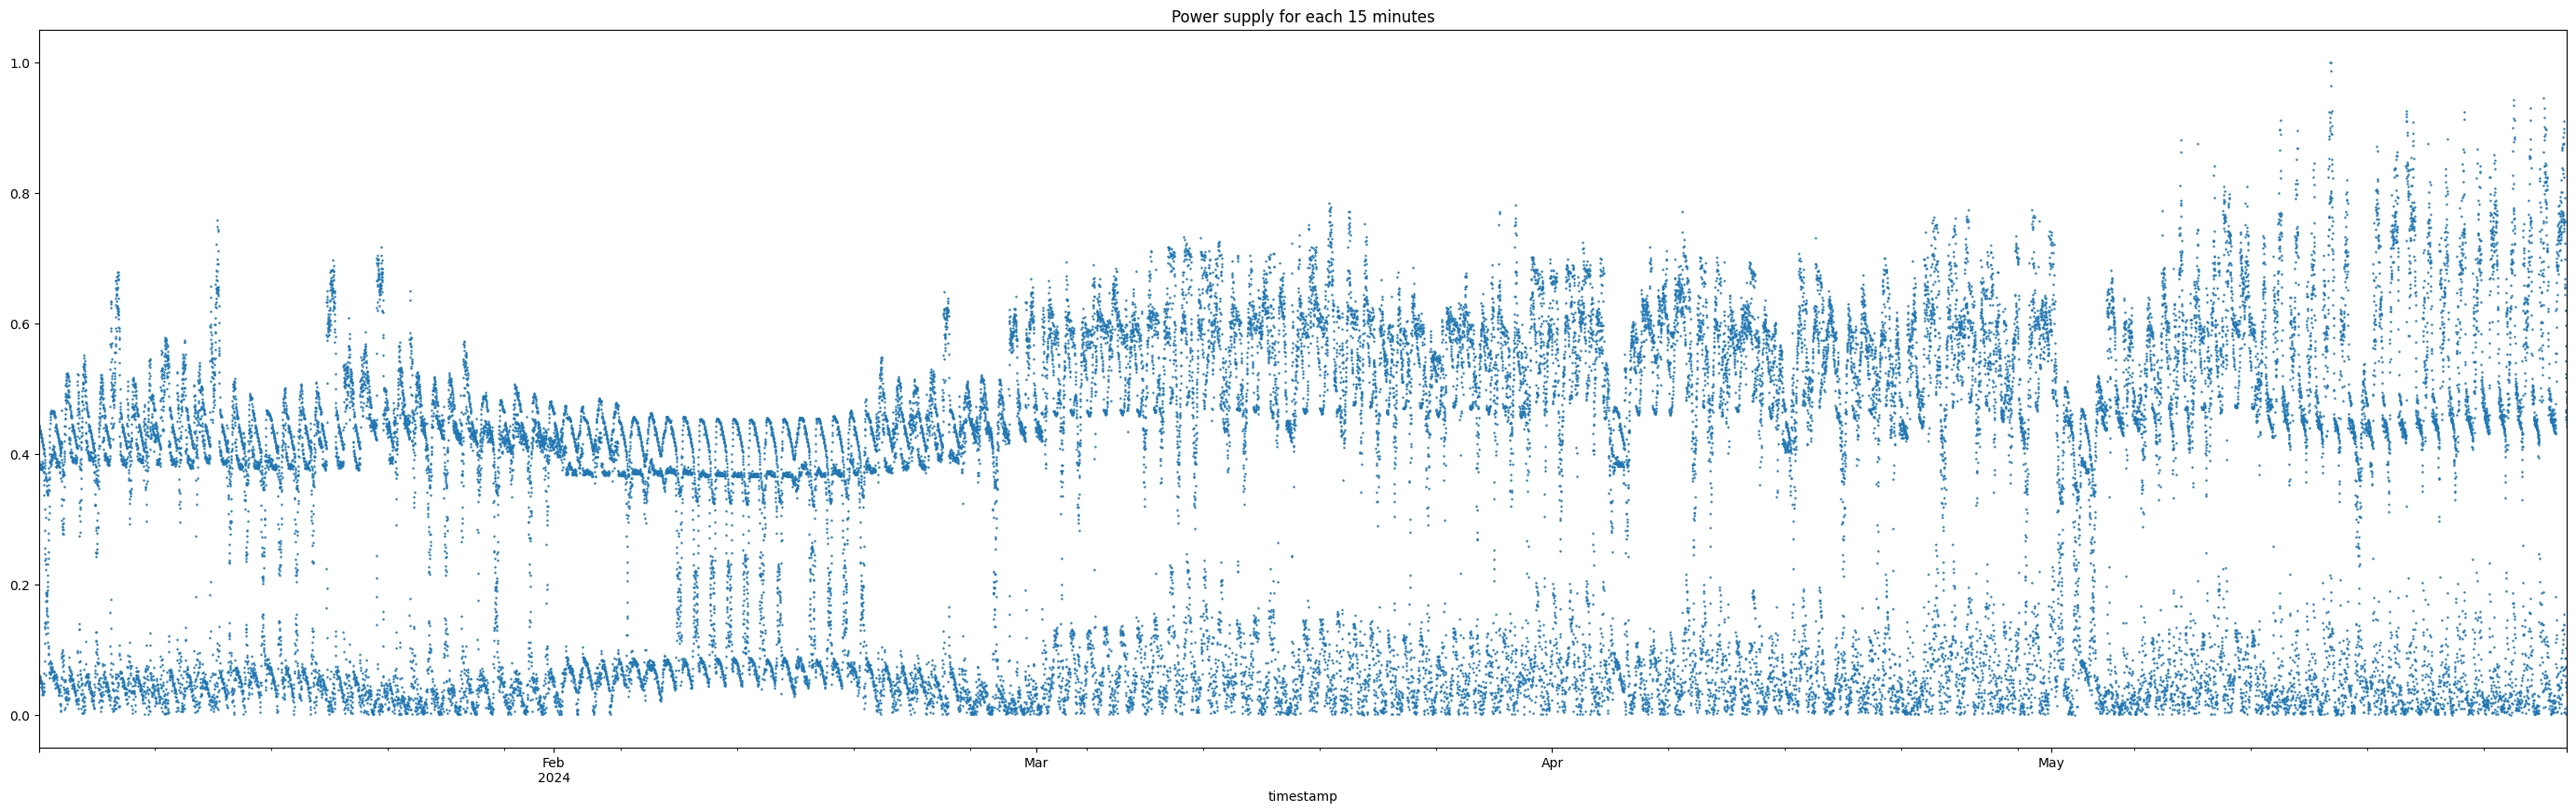

In [ ]:
color_pal = sns.color_palette()
df.plot(style= '.', figsize=(35,10), color=color_pal[0], title= 'Power supply for each 15 minutes', legend= False, ms=1.5 )
plt.show()

<Axes: xlabel='Power Usage', ylabel='Count'>

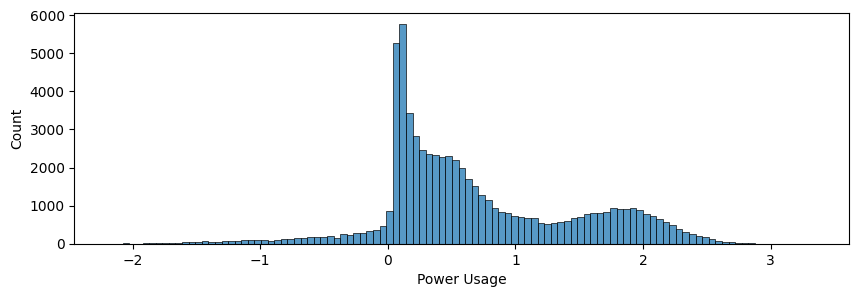

In [ ]:
plt.figure(figsize = (10,3))
sns.histplot(df_long['Power Usage']) #not normally distributed

### Seasonal Plots

In [ ]:
def seasonal_plot(X, y, period, freq, ax=None):
    if ax is None:
        _, ax = plt.subplots()
    palette = sns.color_palette(
        "husl",
        n_colors=X[period].nunique(),
    )
    ax = sns.lineplot(
        x=freq,
        y=y,
        hue=period,
        data=X,
        errorbar=('ci', False),
        ax=ax,
        palette=palette,
        legend=False,
    )
    ax.set_title(f"Seasonal Plot ({period}/{freq})")
    for line, name in zip(ax.lines, X[period].unique()):
        y_ = line.get_ydata()[-1]
        ax.annotate(
            name,
            xy=(1, y_),
            xytext=(6, 0),
            color=line.get_color(),
            xycoords=ax.get_yaxis_transform(),
            textcoords="offset points",
            size=14,
            va="center",
        )
    return ax

In [ ]:
fig, ax = plt.subplots(5, 1, figsize=(30, 50))
seasonal_plot(df_long, y="Power Usage", period="dayofweek", freq="hour", ax = ax[0])
seasonal_plot(df_long, y="Power Usage", period="weekofyear", freq="dayofweek", ax=ax[1])
seasonal_plot(df_long, y="Power Usage", period="month", freq="dayofmonth", ax=ax[2])
seasonal_plot(df_long, y="Power Usage", period="year", freq="quarter", ax=ax[3])
seasonal_plot(df_long, y="Power Usage", period="year", freq="month", ax=ax[4])
plt.show()

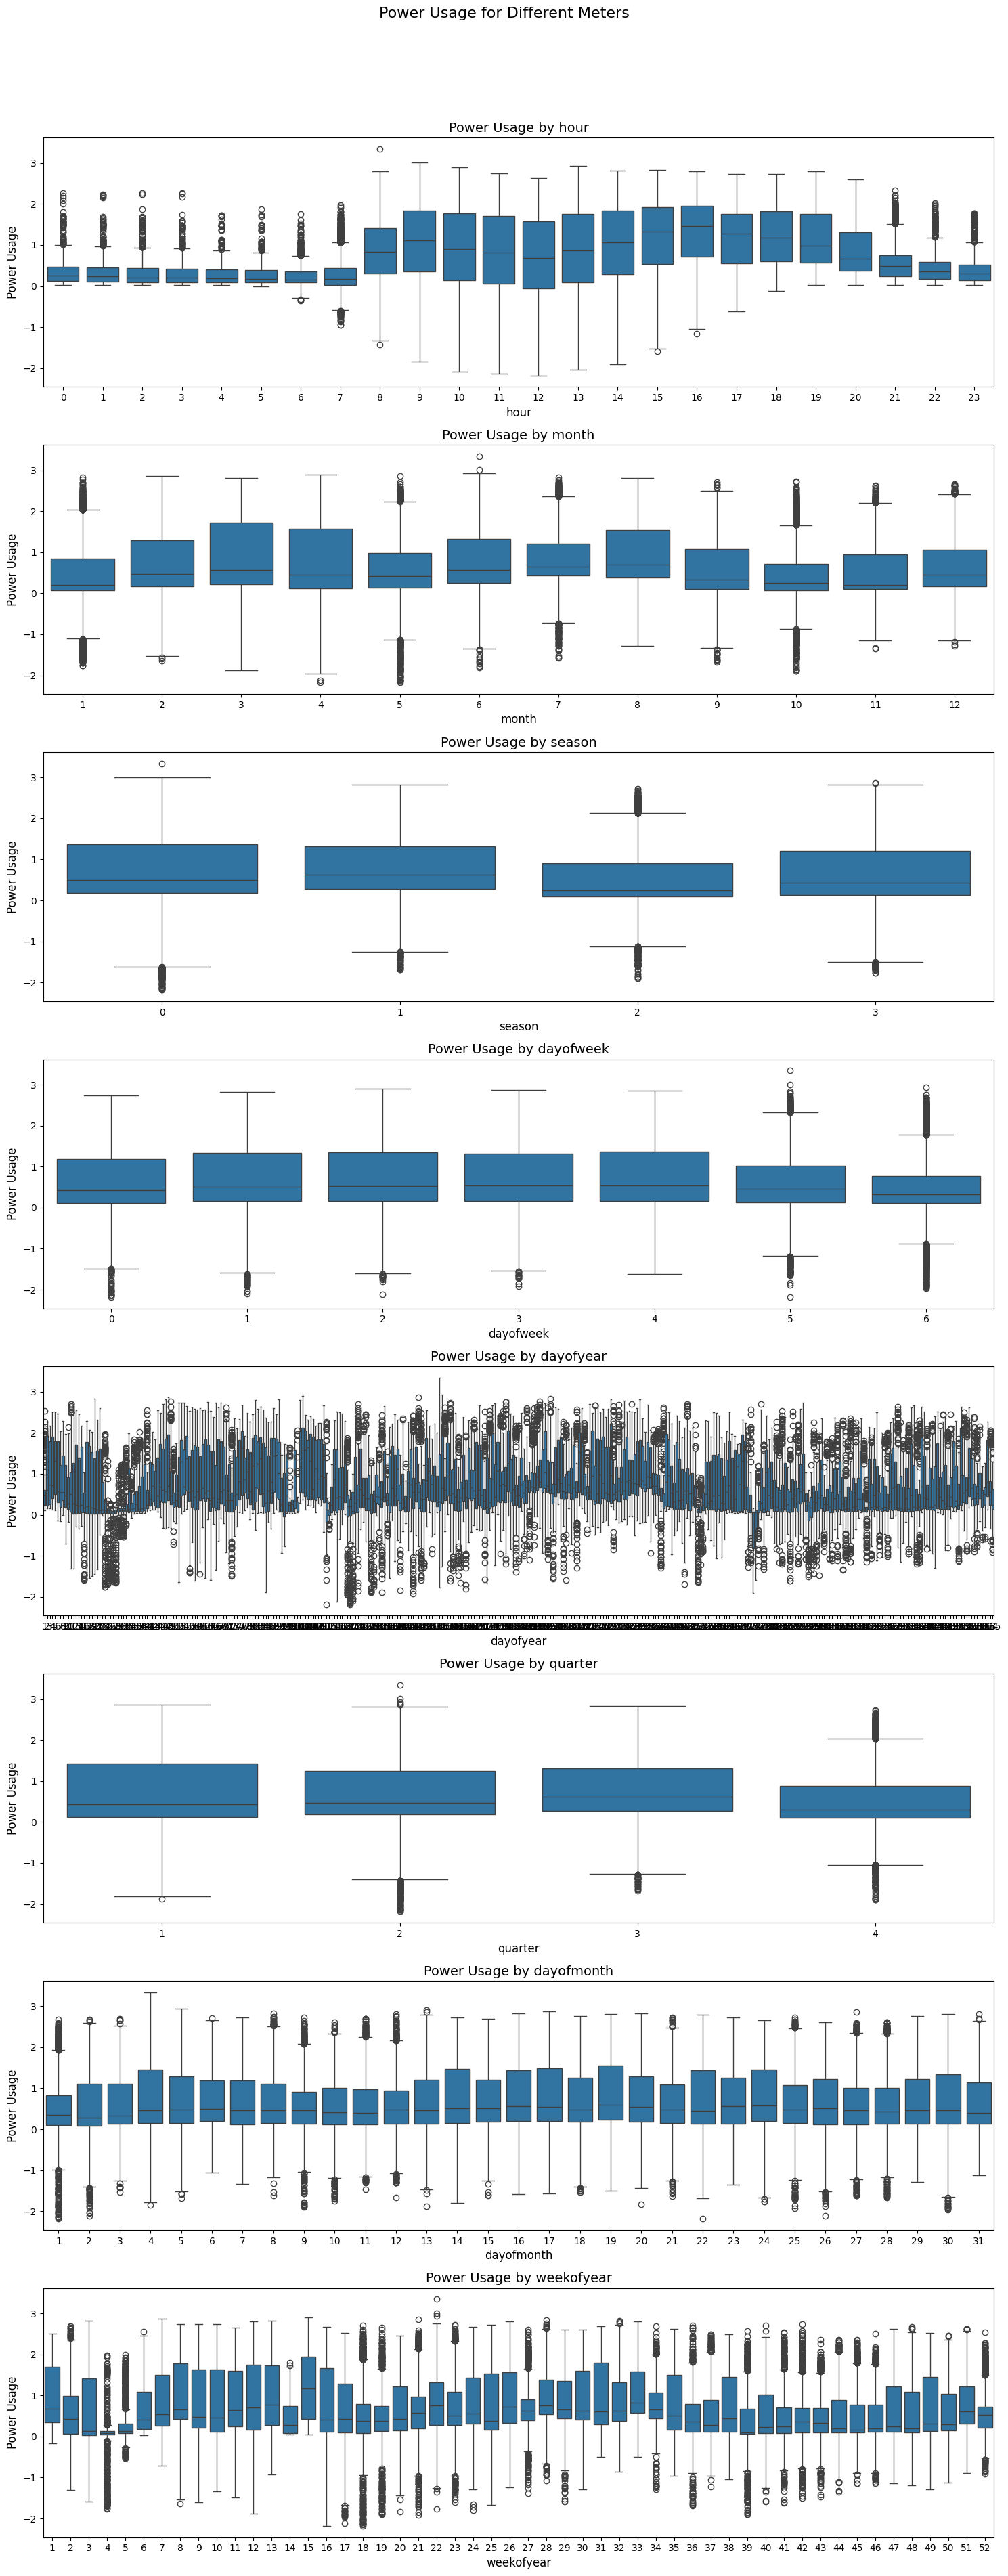

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuration ---
FIG_WIDTH = 15  # Adjust width as needed
FIG_HEIGHT_PER_PLOT = 5  # Adjust height per subplot
VARS_TO_PLOT = ['hour', 'month', 'season', 'dayofweek',
                'dayofyear', 'quarter', 'dayofmonth', 'weekofyear']

# --- Create figure and axes ---
num_plots = len(VARS_TO_PLOT)
fig, axes = plt.subplots(num_plots, 1, figsize=(FIG_WIDTH, num_plots * FIG_HEIGHT_PER_PLOT))
fig.suptitle("Power Usage for Different Meters", fontsize=16)  # Increase title font size

# --- Plot each variable ---
for i, var in enumerate(VARS_TO_PLOT):
    sns.boxplot(x=var, y='Power Usage', data=df_long, ax=axes[i])
    axes[i].set_title(f"Power Usage by {var}", fontsize=14)  # Increase subplot title font size
    axes[i].set_xlabel(var, fontsize=12)  # Increase x-axis label font size
    axes[i].set_ylabel('Power Usage', fontsize=12)  # Increase y-axis label font size

plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust layout for suptitle
plt.show()

### Relationship to the weather

*   No obvious patterns, and almost no **correlation**, not so useful for us


In [ ]:
weather_df =pd.read_csv('/content/weather_data_processed.csv')
weather_df['Date'] = pd.to_datetime(weather_df['Date'])
weather_df = weather_df.set_index('Date')

FileNotFoundError: [Errno 2] No such file or directory: '/content/weather_data_processed.csv'

In [ ]:
df_weather = pd.concat([df,weather_df],axis =1).copy()

In [ ]:
df_weather['Average Power per Day'] = df.iloc[:, :97].mean(axis=1)
df_weather = df_weather.drop(df_weather.columns[:96], axis=1)

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(5,8))

# Subplot 1: High Temp vs. Average Power
axes[0].scatter(df_weather.iloc[:, 0], df_weather['Average Power per Day'], s=1)  # s=1 for small dots
axes[0].set_xlabel('High Temp')
axes[0].set_ylabel('Average Power per Day')
axes[0].set_title('High Temp vs. Average Power')

# Subplot 2: Low Temp vs. Average Power
axes[1].scatter(df_weather.iloc[:, 1], df_weather['Average Power per Day'], s=1)  # s=1 for small dots
axes[1].set_xlabel('Low Temp')
axes[1].set_ylabel('Average Power per Day')
axes[1].set_title('Low Temp vs. Average Power')

# Subplot 3: Precipitation vs. Average Power
axes[2].scatter(df_weather.iloc[:, 2], df_weather['Average Power per Day'], s=1)  # s=1 for small dots
axes[2].set_xlabel('Precipitation')
axes[2].set_ylabel('Average Power per Day')
axes[2].set_title('Precipitation vs. Average Power')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the correlation matrix
correlation_matrix = df_weather.corr()

# Create the heatmap
plt.figure(figsize=(6, 3))  # Adjust figure size if needed
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

# **LSTM MODEL**
From dataframe to Numpy Array


*   Input data needs to be split into X and y
*   X is a 2D np.array (# of records, # of input sequence)
*   y is a 2D np.array (# of records)
*  n_input/ window size is the number for historical imports to be used in forecasting




## Creating Input Data For LSTM

Create Train Test Split

In [ ]:
df_filled.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 67584 entries, 2022-01-01 00:00:00 to 2023-12-31 23:45:00
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Power Usage  67584 non-null  float64 
 1   hour         67584 non-null  int32   
 2   month        67584 non-null  int32   
 3   year         67584 non-null  int32   
 4   dayofweek    67584 non-null  int32   
 5   dayofyear    67584 non-null  int32   
 6   quarter      67584 non-null  int32   
 7   dayofmonth   67584 non-null  int32   
 8   weekofyear   67584 non-null  UInt32  
 9   date_offset  67584 non-null  int32   
 10  season       67584 non-null  category
 11  hour_sin     67584 non-null  float64 
 12  hour_cos     67584 non-null  float64 
 13  month_sin    67584 non-null  float64 
 14  month_cos    67584 non-null  float64 
 15  week_sin     67584 non-null  float64 
 16  week_cos     67584 non-null  float64 
dtypes: UInt32(1), category(1), float64

In [ ]:
df_model_train = df_filled[['Power Usage','season','month','hour','year','week_sin','week_cos']].copy()
df_model_test = df_val_filled[['Power Usage','season', 'month','hour','year','week_sin','week_cos']].copy()

# Downsample to hourly frequency using the mean
#df_model2 = df_model2.resample('h').mean() #resample produce Nans
#df_model2 = df_model2.interpolate(method='linear')  # Linear interpolation

In [ ]:
df_model_test

,Power Usage,season,month,hour,year,week_sin,week_cos
timestamp,,,,,,,
2024-01-01 00:00:00,0.1367,3,1,0,2024,0.000000,1.000000
2024-01-01 00:15:00,0.2140,3,1,0,2024,0.000000,1.000000
2024-01-01 00:30:00,0.1263,3,1,0,2024,0.000000,1.000000
2024-01-01 00:45:00,0.1227,3,1,0,2024,0.000000,1.000000
2024-01-01 01:00:00,0.1743,3,1,1,2024,0.000000,1.000000
...,...,...,...,...,...,...,...
2024-05-31 22:45:00,0.5892,0,5,22,2024,-0.433884,-0.900969
2024-05-31 23:00:00,0.5126,0,5,23,2024,-0.433884,-0.900969
2024-05-31 23:15:00,0.5658,0,5,23,2024,-0.433884,-0.900969


In [ ]:
#data normalization, MinMax is better for LSTM
scaler = MinMaxScaler() #StandardScaler()
df_model_train['Power Usage'] = scaler.fit_transform(df_model_train['Power Usage'].values.reshape(-1,1))
#1d->2d: reshape number of rows to auto fit all data, 1 should be one col

In [ ]:
df_model_train

,Power Usage,season,month,hour,year,week_sin,week_cos
timestamp,,,,,,,
2022-01-01 00:00:00,0.489414,3,1,0,2022,-0.974928,-0.222521
2022-01-01 00:15:00,0.488436,3,1,0,2022,-0.974928,-0.222521
2022-01-01 00:30:00,0.483346,3,1,0,2022,-0.974928,-0.222521
2022-01-01 00:45:00,0.498868,3,1,0,2022,-0.974928,-0.222521
2022-01-01 01:00:00,0.488744,3,1,1,2022,-0.974928,-0.222521
...,...,...,...,...,...,...,...
2023-12-31 22:45:00,0.440349,3,12,22,2023,-0.781831,0.623490
2023-12-31 23:00:00,0.431438,3,12,23,2023,-0.781831,0.623490
2023-12-31 23:15:00,0.423216,3,12,23,2023,-0.781831,0.623490


In [ ]:
#data normalization, MinMax is better for LSTM
scaler = MinMaxScaler() #StandardScaler()
df_model_test['Power Usage'] = scaler.fit_transform(df_model_test['Power Usage'].values.reshape(-1,1)) #1d->2d: reshape number of rows to auto fit all data, 1 should be one col

In [ ]:
df_model_test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 14592 entries, 2024-01-01 00:00:00 to 2024-05-31 23:45:00
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   Power Usage  14592 non-null  float64 
 1   season       14592 non-null  category
 2   month        14592 non-null  int32   
 3   hour         14592 non-null  int32   
 4   year         14592 non-null  int32   
 5   week_sin     14592 non-null  float64 
 6   week_cos     14592 non-null  float64 
dtypes: category(1), float64(3), int32(3)
memory usage: 641.4 KB


In [ ]:
# [[[power supplt, sin], [power, sin], [power sin], [power,sin], [power,sin]]] ->  [power]
# [[[2], [3], [4], [5], [6]]] [7]
# [[[3], [4], [5], [6], [7]]] [8]

def create_sequences(df, target_column, window_size=4):
    df_as_np = df.to_numpy()
    X = []
    y = []
    for i in range(len(df_as_np) - window_size):
        row = df_as_np[i : i + window_size]
        X.append(row)
        label = df_as_np[i + window_size, df.columns.get_loc(target_column)]  # Get target column index
        y.append(label)
    return np.array(X), np.array(y)

In [ ]:
window_size = 4 #5 hours prev value
X_train, y_train = create_sequences(df_model_train, 'Power Usage', window_size)
X_test, y_test = create_sequences(df_model_test, 'Power Usage', window_size)

X_train, X_val, y_train, y_val = train_test_split(X_train,y_train,test_size=0.2, random_state = 42)

X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((54064, 4, 7), (54064,), (13516, 4, 7), (13516,), (14588, 4, 7), (14588,))

## Building the LSTM Model



*   first LSTM layer learns hourly, daily patterns.
*   Dropout layer is added to prevent overfitting
*   second LSTM layer learns weekly, monthly patterns.
*   too much LSTM layers might caught overfitting and analysing noises.  



In [ ]:
#Building the LSTM model
n_input = X_train.shape[1] #window size
n_features = X_train.shape[2] #number of features

model2 = keras.Sequential()
model2.add(LSTM(units=100, return_sequences = True, input_shape = (n_input, n_features)))
model2.add(Dropout(0.3)) #dropout layer manages overfitting
model2.add(LSTM(units=64, return_sequences= True))
model2.add(Dropout(0.3)) #dropout layer manages overfitting
model2.add(LSTM(units=50, return_sequences= False))
model2.add(Dropout(0.3)) #dropout layer manages overfitting
model2.add(Dense(8, activation = 'relu'))
model2.add(Dense(1, activation = 'linear'))

model2.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 4, 100)         │        43,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 4, 64)          │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 50)             │        23,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,857 (425.22 KB)

 Trainable params: 108,857 (425.22 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#early stopping condition to prevent overfitting, val_loss starts to increase while training loss continues to decrease
early_stopping = EarlyStopping(monitor = 'val_loss',
                               patience = 2,
                               restore_best_weights = True ) # patience is number of epochs it will continue even if it didn't improve

In [ ]:
model2.compile(optimizer=Adam(learning_rate=1e-4) ,
              loss = 'mean_squared_error',
              metrics = ['RootMeanSquaredError'])

In [ ]:
model2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, callbacks=early_stopping)

Epoch 1/100
1690/1690 ━━━━━━━━━━━━━━━━━━━━ 29s 13ms/step - RootMeanSquaredError: 0.1850 - loss: 0.0355 - val_RootMeanSquaredError: 0.1323 - val_loss: 0.0175
Epoch 2/100
1690/1690 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - RootMeanSquaredError: 0.1428 - loss: 0.0204 - val_RootMeanSquaredError: 0.1301 - val_loss: 0.0169
Epoch 3/100
1690/1690 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - RootMeanSquaredError: 0.1377 - loss: 0.0190 - val_RootMeanSquaredError: 0.1298 - val_loss: 0.0168
Epoch 4/100
1690/1690 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - RootMeanSquaredError: 0.1341 - loss: 0.0180 - val_RootMeanSquaredError: 0.1290 - val_loss: 0.0166
Epoch 5/100
1690/1690 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - RootMeanSquaredError: 0.1324 - loss: 0.0175 - val_RootMeanSquaredError: 0.1264 - val_loss: 0.0160
Epoch 6/100
1690/1690 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - RootMeanSquaredError: 0.1294 - loss: 0.0167 - val_RootMeanSquaredError: 0.1247 - val_loss: 0.0156
Epoch 7/100
1690/1690 ━━━━━━━━━━━━━━━━━━━━ 40s 13ms/step -

<Axes: >

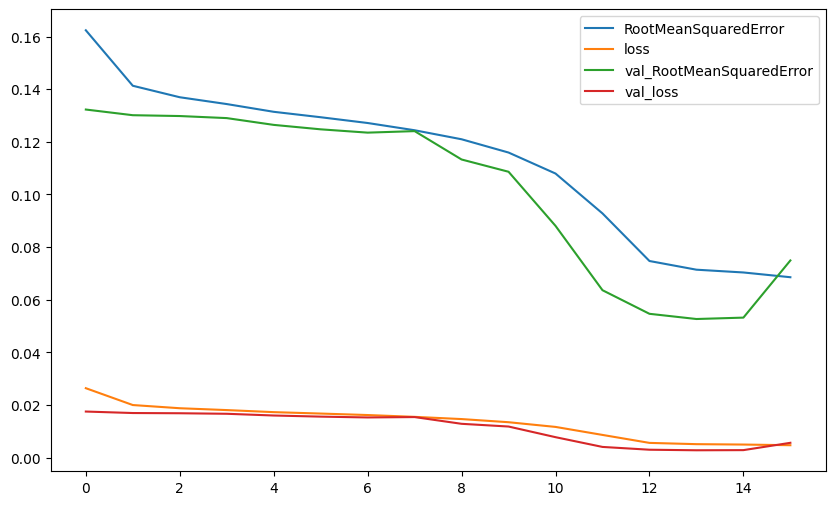

In [ ]:
losses_df = pd.DataFrame(model2.history.history)
losses_df.plot(figsize = (10,6))

## Prediction

In [ ]:
#save model
from tensorflow.keras.models import save_model,load_model
save_model(model2,'lstm_model_multivariate_week_trig.keras')
lstm_model = load_model('lstm_model_multivariate_weeek_trig.keras')


ValueError: File not found: filepath=lstm_model_multivariate_weeek_trig.keras. Please ensure the file is an accessible `.keras` zip file.

Save and Reuse Model

In [ ]:
def plot_predictions(model, X, y_scaled, scaler, start=0, end=1000):
    predictions = model.predict(X)

    # Ensure predictions and y are 2D for inverse_transform
    if predictions.ndim == 1:
        predictions = predictions.reshape(-1, 1)
    if y_scaled.ndim == 1:
        y_scaled = y_scaled.reshape(-1, 1)

    # Inverse transform
    predictions_actual = scaler.inverse_transform(predictions).flatten()
    y_actual = scaler.inverse_transform(y_scaled).flatten()

    # Now they're both 1D
    df = pd.DataFrame(data={
        'date': df_model_test.index,
        'Predictions': predictions_actual,
        'Actuals': y_actual
    })

    # Plot
    plt.plot(df['Actuals'][start:end], label='Actuals')
    plt.plot(df['Predictions'][start:end], label='Predictions',color='r',linestyle ='--')
    plt.title("Plots of actual value vs predictions")
    plt.legend()
    plt.show()

    # Evaluation
    rmse = np.sqrt(mse(y_actual, predictions_actual))
    mae_value = mae(y_actual, predictions_actual)
    mape_value = smape(y_actual, predictions_actual)

    print(f"The root mean square error (RMSE) is: {rmse:.2f}")
    print(f"The mean absolute error (MAE) is: {mae_value:.2f}")
    print(f"The mean absolute percentage error (sMAPE) is: {mape_value:.2f}%")

    return df, rmse, mae_value, mape_value

In [ ]:
X_test.shape

(14588, 4, 7)

456/456 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


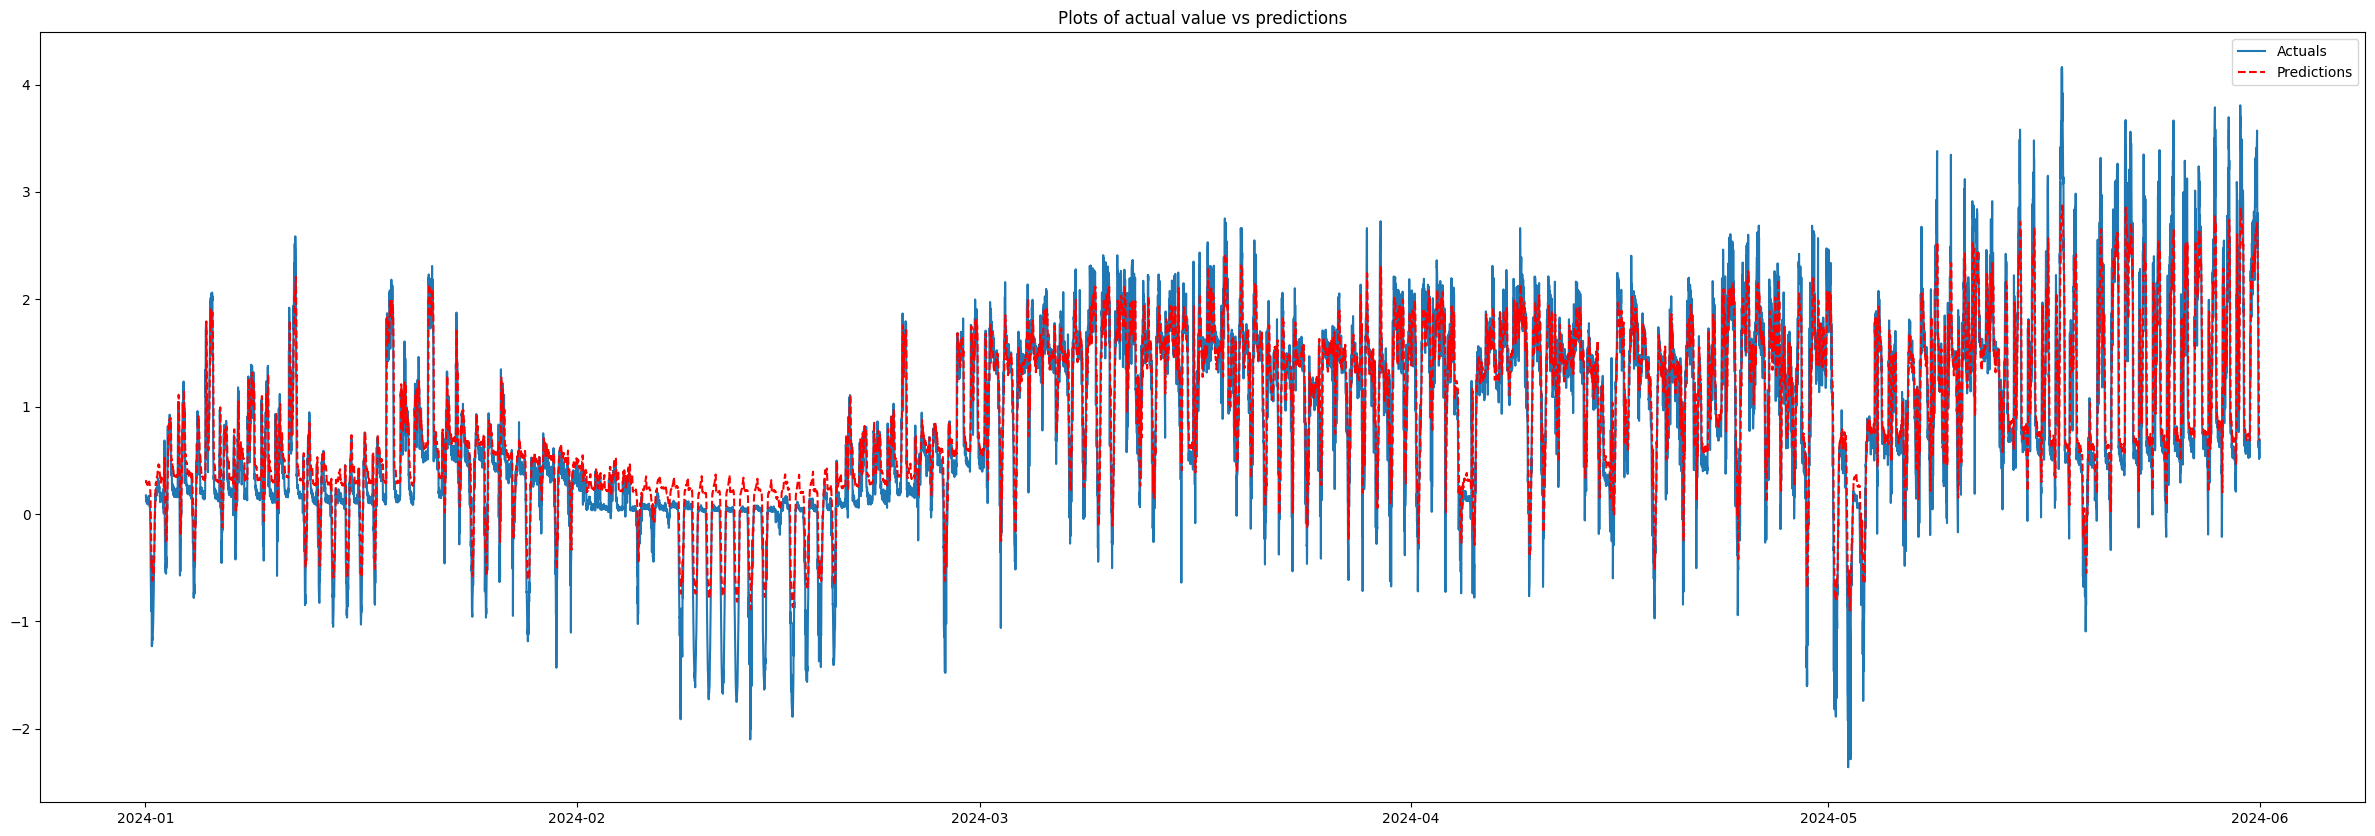

The root mean square error (RMSE) is: 0.32
The mean absolute error (MAE) is: 0.23
The mean absolute percentage error (sMAPE) is: 44.69%


In [ ]:

#inverse scaling
predictions = model2.predict(X_test)
predictions_rescaled = scaler.inverse_transform(predictions).flatten()

y_test_rescaled = scaler.inverse_transform(y_test.reshape(-1,1))
y_test_rescaled = y_test_rescaled.flatten() # Now y_test contains actual values

# Keep only timestamps that correspond to predictions
# Drop the first `window_size` timestamps because they were used for input
timestamps = df_model_test.index[window_size:].to_list()


# Create result DataFrame with timestamps
df = pd.DataFrame({
    'timestamp': timestamps,
    'predictions': predictions_rescaled,
    'actual': y_test_rescaled
})

df['date'] = pd.to_datetime(df['timestamp']).dt.date
df.set_index('timestamp', inplace=True)

plt.figure(figsize=(30, 10))  # Set the size of the figure here
plt.plot(df['actual'], label='Actuals')
plt.plot(df['predictions'], label='Predictions',color='r',linestyle ='--')
plt.title("Plots of actual value vs predictions")
plt.legend()
plt.show()

# Evaluation
rmse = np.sqrt(mse(y_test_rescaled, predictions_rescaled))
mae_value = mae(y_test_rescaled, predictions_rescaled)
mape_value = smape(y_test_rescaled, predictions_rescaled)

print(f"The root mean square error (RMSE) is: {rmse:.2f}")
print(f"The mean absolute error (MAE) is: {mae_value:.2f}")
print(f"The mean absolute percentage error (sMAPE) is: {mape_value:.2f}%")

In [ ]:
# Add a date column for grouping
# Group by date and compute mean absolute error
df['error'] = np.abs(df['actual'] - df['predictions'])

print('Worst Prediction Dates:')
display(df.groupby('date')['error'].mean().sort_values(ascending=False).head())

print('\nBest Prediction Dates:')
display(df.groupby('date')['error'].mean().sort_values(ascending=True).head())

Worst Prediction Dates:


,error
date,
2024-05-01,0.436185
2024-05-30,0.419837
2024-05-17,0.413575
2024-02-16,0.409799
2024-05-02,0.390993



Best Prediction Dates:


,error
date,
2024-02-26,0.104185
2024-01-29,0.109543
2024-02-04,0.124233
2024-02-03,0.125721
2024-01-27,0.126021


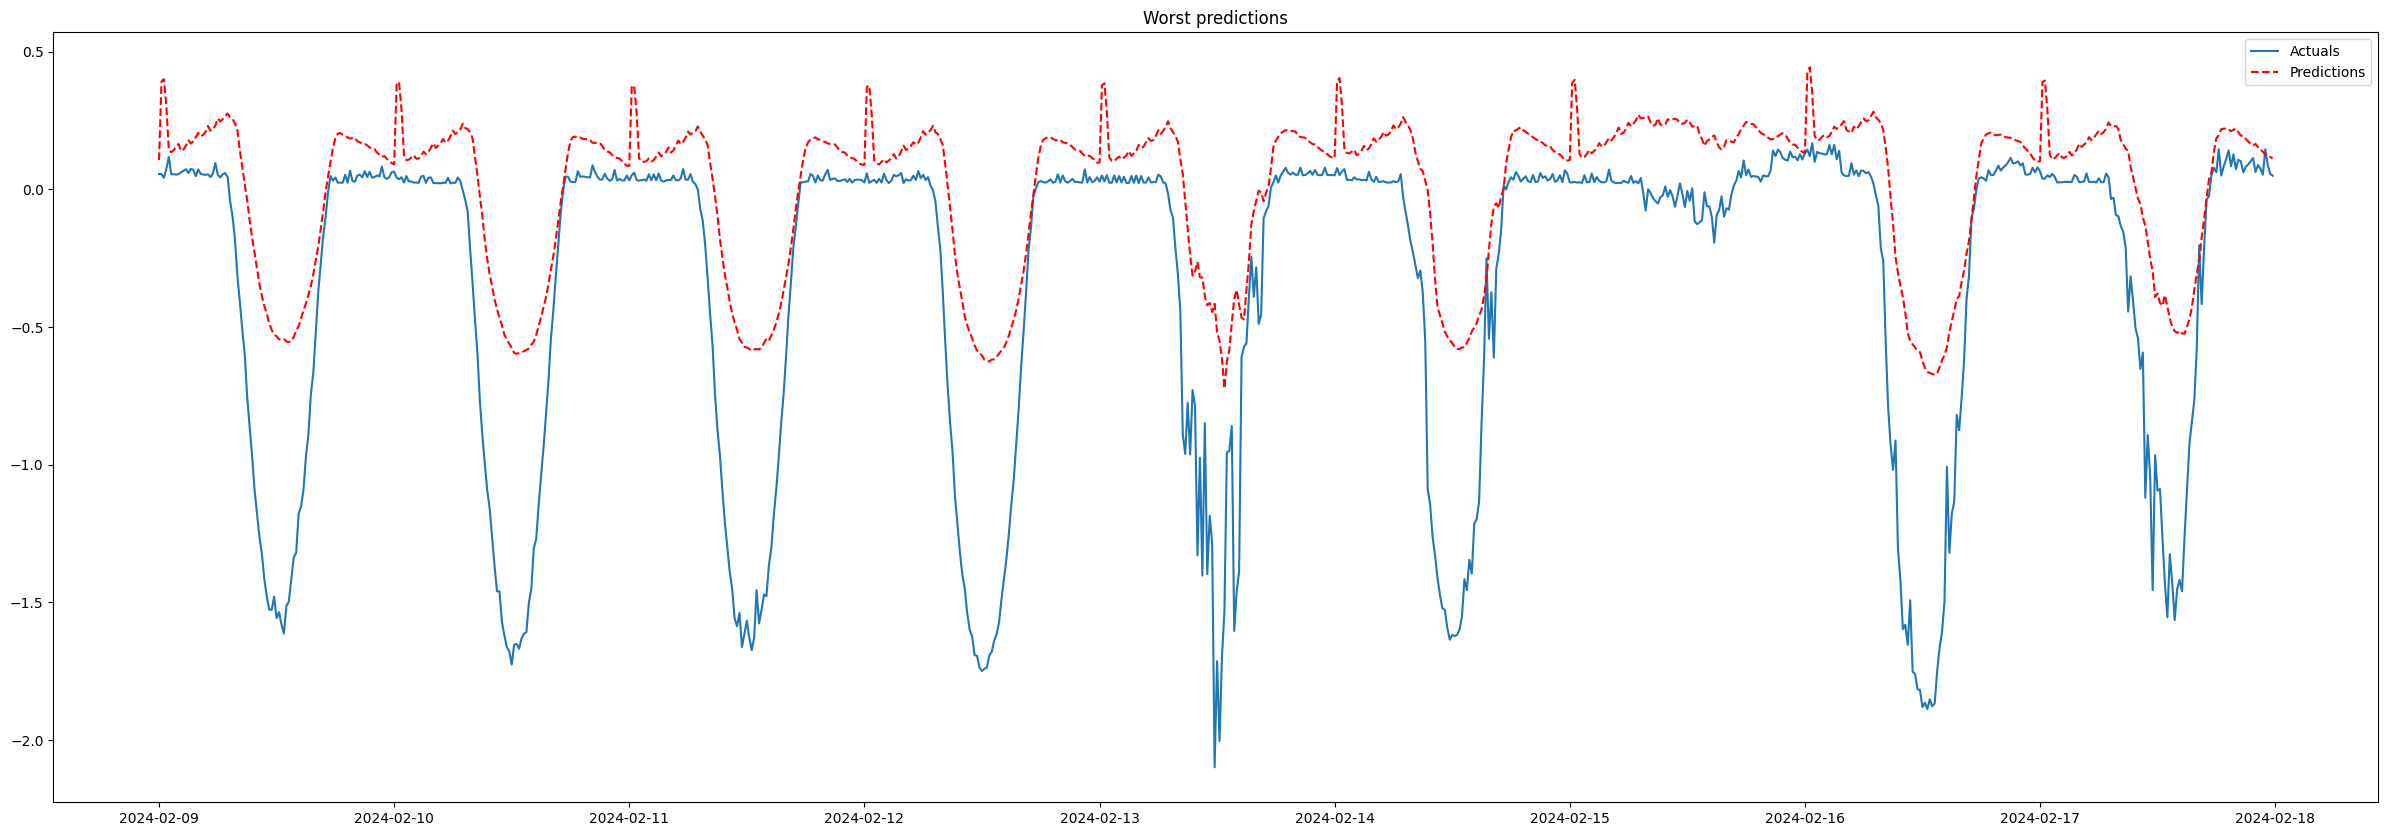

In [ ]:
plt.figure(figsize=(30, 10))  # Set the size of the figure here
plt.plot(df['actual']['2024-02-09':'2024-02-17'], label='Actuals')
plt.plot(df['predictions']['2024-02-09':'2024-02-17'], label='Predictions',color='r',linestyle ='--')
plt.title("Worst predictions")
plt.legend()
plt.show()

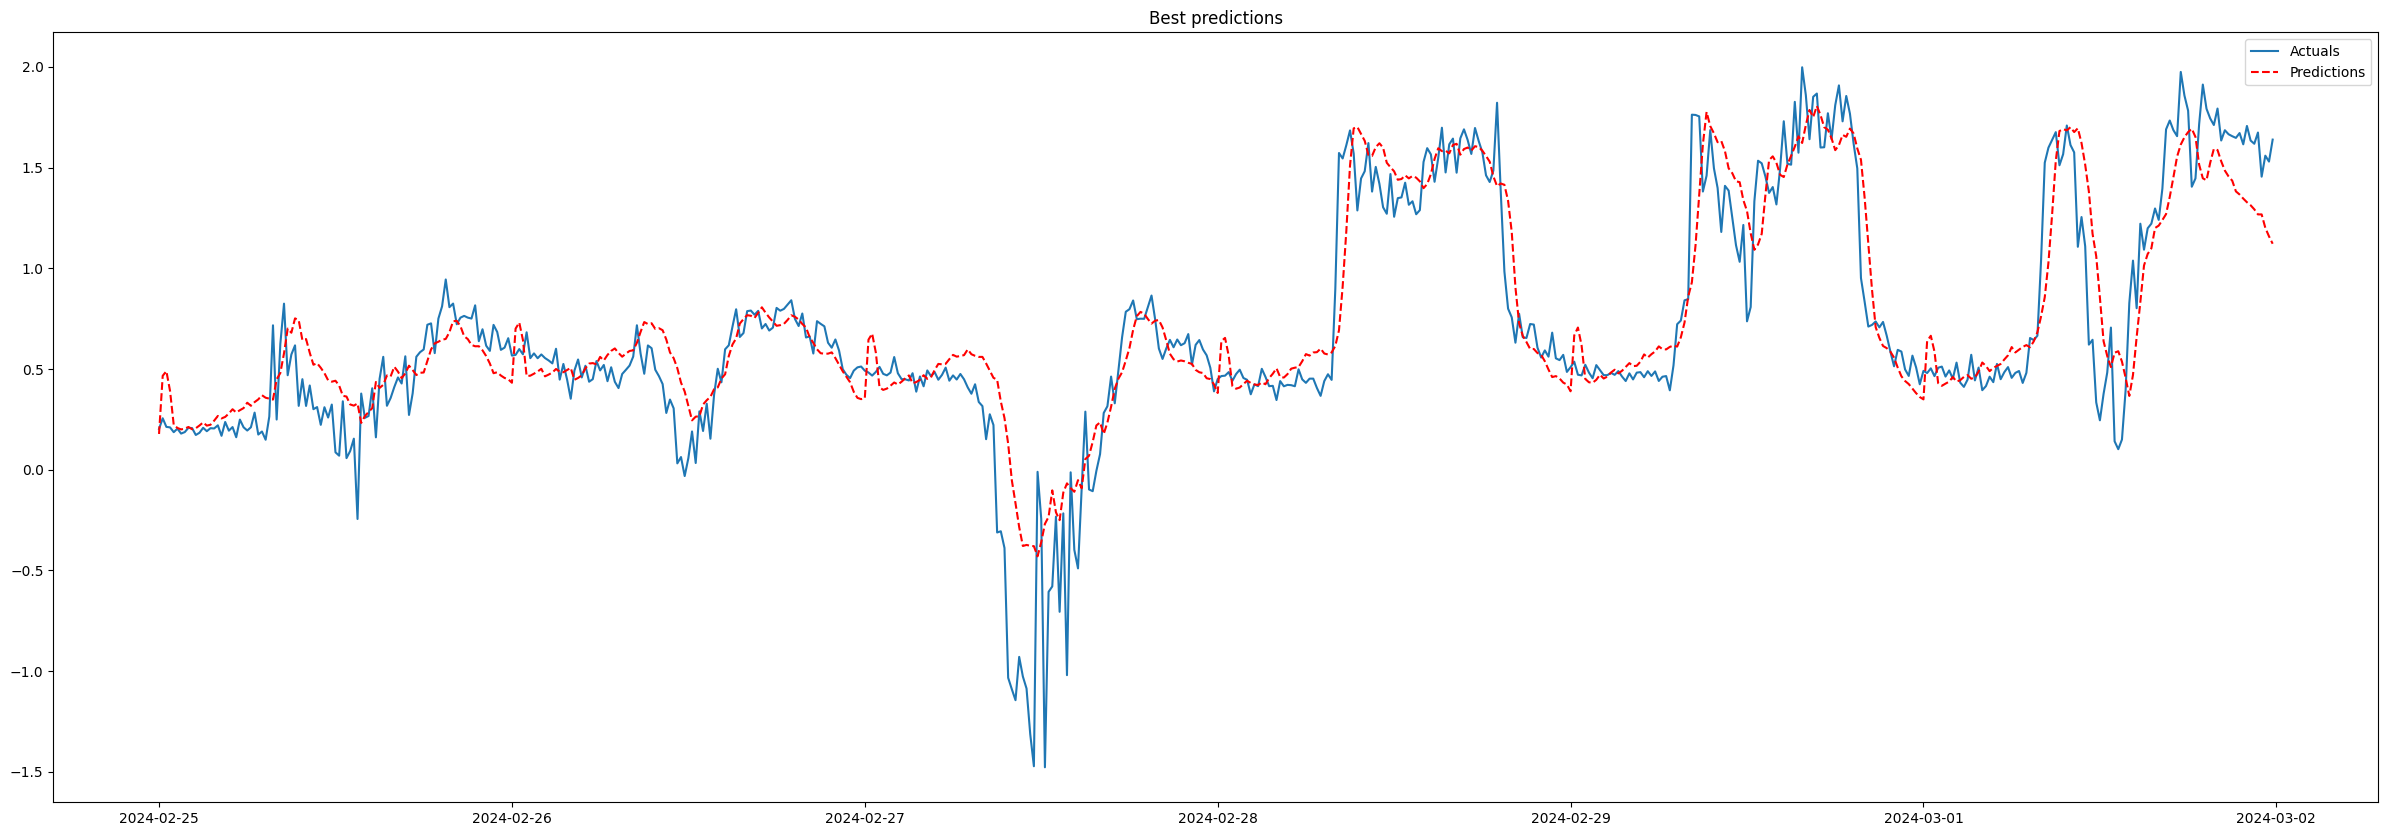

In [ ]:
plt.figure(figsize=(30, 10))  # Set the size of the figure here
plt.plot(df['actual']['2024-02-25':'2024-03-01'], label='Actuals')
plt.plot(df['predictions']['2024-02-25':'2024-03-01'], label='Predictions',color='r',linestyle ='--')
plt.title("Best predictions")
plt.legend()
plt.show()

XGBoost Model

In [ ]:
#for cross validation
from sklearn.model_selection import TimeSeriesSplit

#import models for xgboost
import xgboost as xgb

In [ ]:
train = df_filled
test = df_val_filled

features_xgb_reg = ['season','month','hour','year','week_cos','week_sin']
target = ['Power Usage']

tss = TimeSeriesSplit(n_splits=5, test_size=24*182*1, gap=24)
train = train.sort_index()

#lists to store data for each CV
scores = []
preds = []

#train the model on 5 seperate train, eval splits to find the best parameters and observe performance
for train_idx, eval_idx in tss.split(train):
    train_set = train.iloc[train_idx]
    eval_set = train.iloc[eval_idx]

    X_train = train_set[features_xgb_reg]
    y_train = train_set[target]
    X_eval = eval_set[features_xgb_reg]
    y_eval = eval_set[target]

    #define the model
    xgb_reg = xgb.XGBRegressor(n_estimators=1000, enable_categorical=True,
                                max_depth= 10, booster='gbtree',
                                early_stopping_rounds=10, base_score=0.5,
                                min_child_weight= 2, #avoid splitting when child is a few, smaller number leads to overfitting
                                gamma = 0.2, #Requires more gain before splitting, avoid overfitting
                                objective='reg:squarederror', learning_rate=1e-2, colsample_bytree= 0.5) #larger better test set MAPE, #'colsample_bytree','subsample'

#reg_lambda=1.5, reg_alpha=0.5
    #train the model
    history = xgb_reg.fit(X_train, y_train,
                eval_set = [(X_train, y_train), (X_eval, y_eval)],
                verbose=100) #early_stopping_rounds=10)

    y_pred = xgb_reg.predict(X_eval)
    preds.append(y_pred)
    score = mape(y_eval, y_pred)
    scores.append(score)

[0]	validation_0-rmse:0.82555	validation_1-rmse:0.69868
[90]	validation_0-rmse:0.66066	validation_1-rmse:0.67284
[0]	validation_0-rmse:0.81523	validation_1-rmse:0.76059
[100]	validation_0-rmse:0.65324	validation_1-rmse:0.68193
[200]	validation_0-rmse:0.58432	validation_1-rmse:0.65579
[273]	validation_0-rmse:0.55982	validation_1-rmse:0.64964
[0]	validation_0-rmse:0.81091	validation_1-rmse:0.70500
[100]	validation_0-rmse:0.65510	validation_1-rmse:0.63762
[172]	validation_0-rmse:0.60337	validation_1-rmse:0.62778
[0]	validation_0-rmse:0.80354	validation_1-rmse:0.65022
[100]	validation_0-rmse:0.65378	validation_1-rmse:0.59295
[108]	validation_0-rmse:0.64816	validation_1-rmse:0.59382
[0]	validation_0-rmse:0.79387	validation_1-rmse:0.64348
[100]	validation_0-rmse:0.64937	validation_1-rmse:0.58480
[200]	validation_0-rmse:0.58627	validation_1-rmse:0.56454
[300]	validation_0-rmse:0.55662	validation_1-rmse:0.56045
[306]	validation_0-rmse:0.55599	validation_1-rmse:0.56064


In [ ]:
print(f'Average of all the MAPE scores for Cross Validation: {np.mean(scores) : 0.4f}')
print(f'Fold Scores: {scores}')

Average of all the MAPE scores for Cross Validation:  81114194.6484
Fold Scores: [np.float64(118005361.27035636), np.float64(287564650.8926052), np.float64(362.26661022167343), np.float64(269.06301266029953), np.float64(329.7496382495877)]


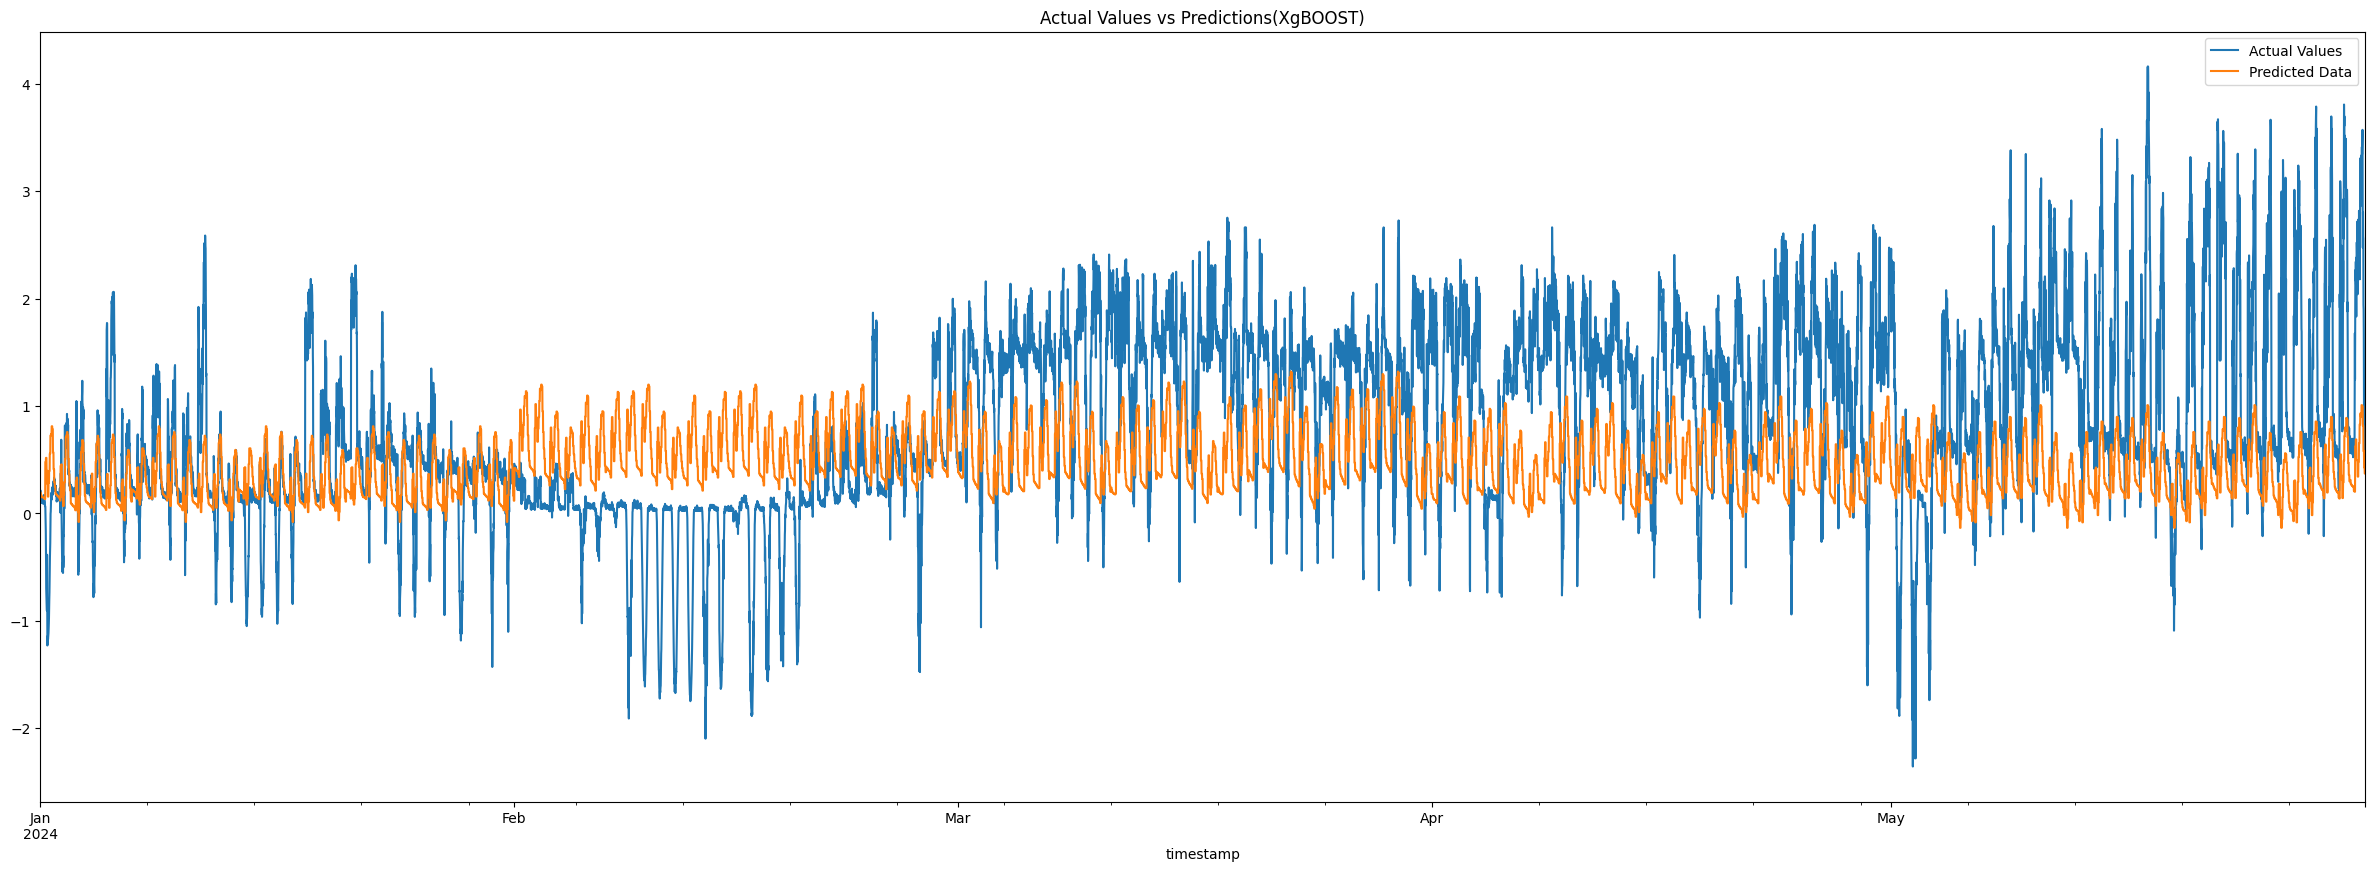

The root mean square error (RMSE) is: 0.96
The mean absolute error (MAE) is: 0.76
The mean absolute percentage error (sMAPE) is: 106.58%


In [ ]:
X_test = test[features_xgb_reg]
y_test = test[target]

test['predictions'] = xgb_reg.predict(X_test)
#df = df.merge(test[['predictions']], how='left', left_index=True, right_index=True)

ax = y_test.plot(figsize=(30,10))
test['predictions'].plot(ax=ax)
plt.legend(['Actual Values', 'Predicted Data'])
plt.title("Actual Values vs Predictions(XgBOOST)")
plt.show()

# Evaluation
mse_score= mse(test['Power Usage'], test['predictions'])
rmse = np.sqrt(mse_score)
mae_value = mae(test['Power Usage'], test['predictions'])
mape_value = smape(test['Power Usage'], test['predictions'])

print(f"The root mean square error (RMSE) is: {rmse:.2f}")
print(f"The mean absolute error (MAE) is: {mae_value:.2f}")
print(f"The mean absolute percentage error (sMAPE) is: {mape_value:.2f}%")

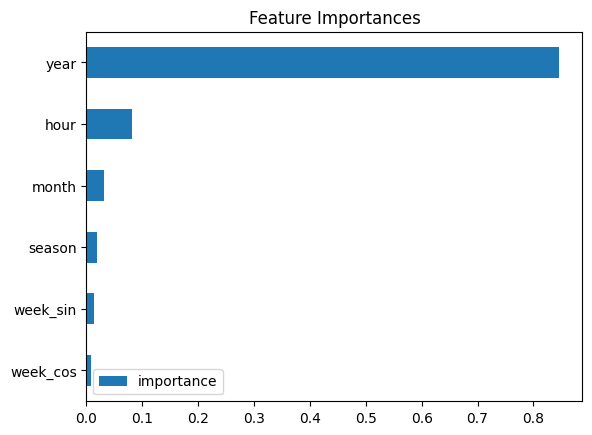

In [ ]:
feat_imp = pd.DataFrame(data=xgb_reg.feature_importances_,
                        index = xgb_reg.feature_names_in_,
                        columns=['importance'])
feat_imp.sort_values('importance').plot(kind = 'barh')
plt.title("Feature Importances")
plt.show()

In [ ]:
test['error'] = np.abs(test[target[0]] - test['predictions'])
test['date'] = test.index.date
print('Worst Predictions:')
display(test.groupby(['date'])['error'].mean().sort_values(ascending=False).head())
print('\nBest Predictions:')
display(test.groupby(['date'])['error'].mean().sort_values(ascending=True).head())

Worst Predictions:


,error
date,
2024-05-12,1.601223
2024-05-11,1.570025
2024-03-17,1.449572
2024-05-22,1.376623
2024-05-27,1.376618



Best Predictions:


,error
date,
2024-01-07,0.134011
2024-01-02,0.154445
2024-01-06,0.162430
2024-01-09,0.177644
2024-02-25,0.180271


<Figure size 2000x1000 with 0 Axes>

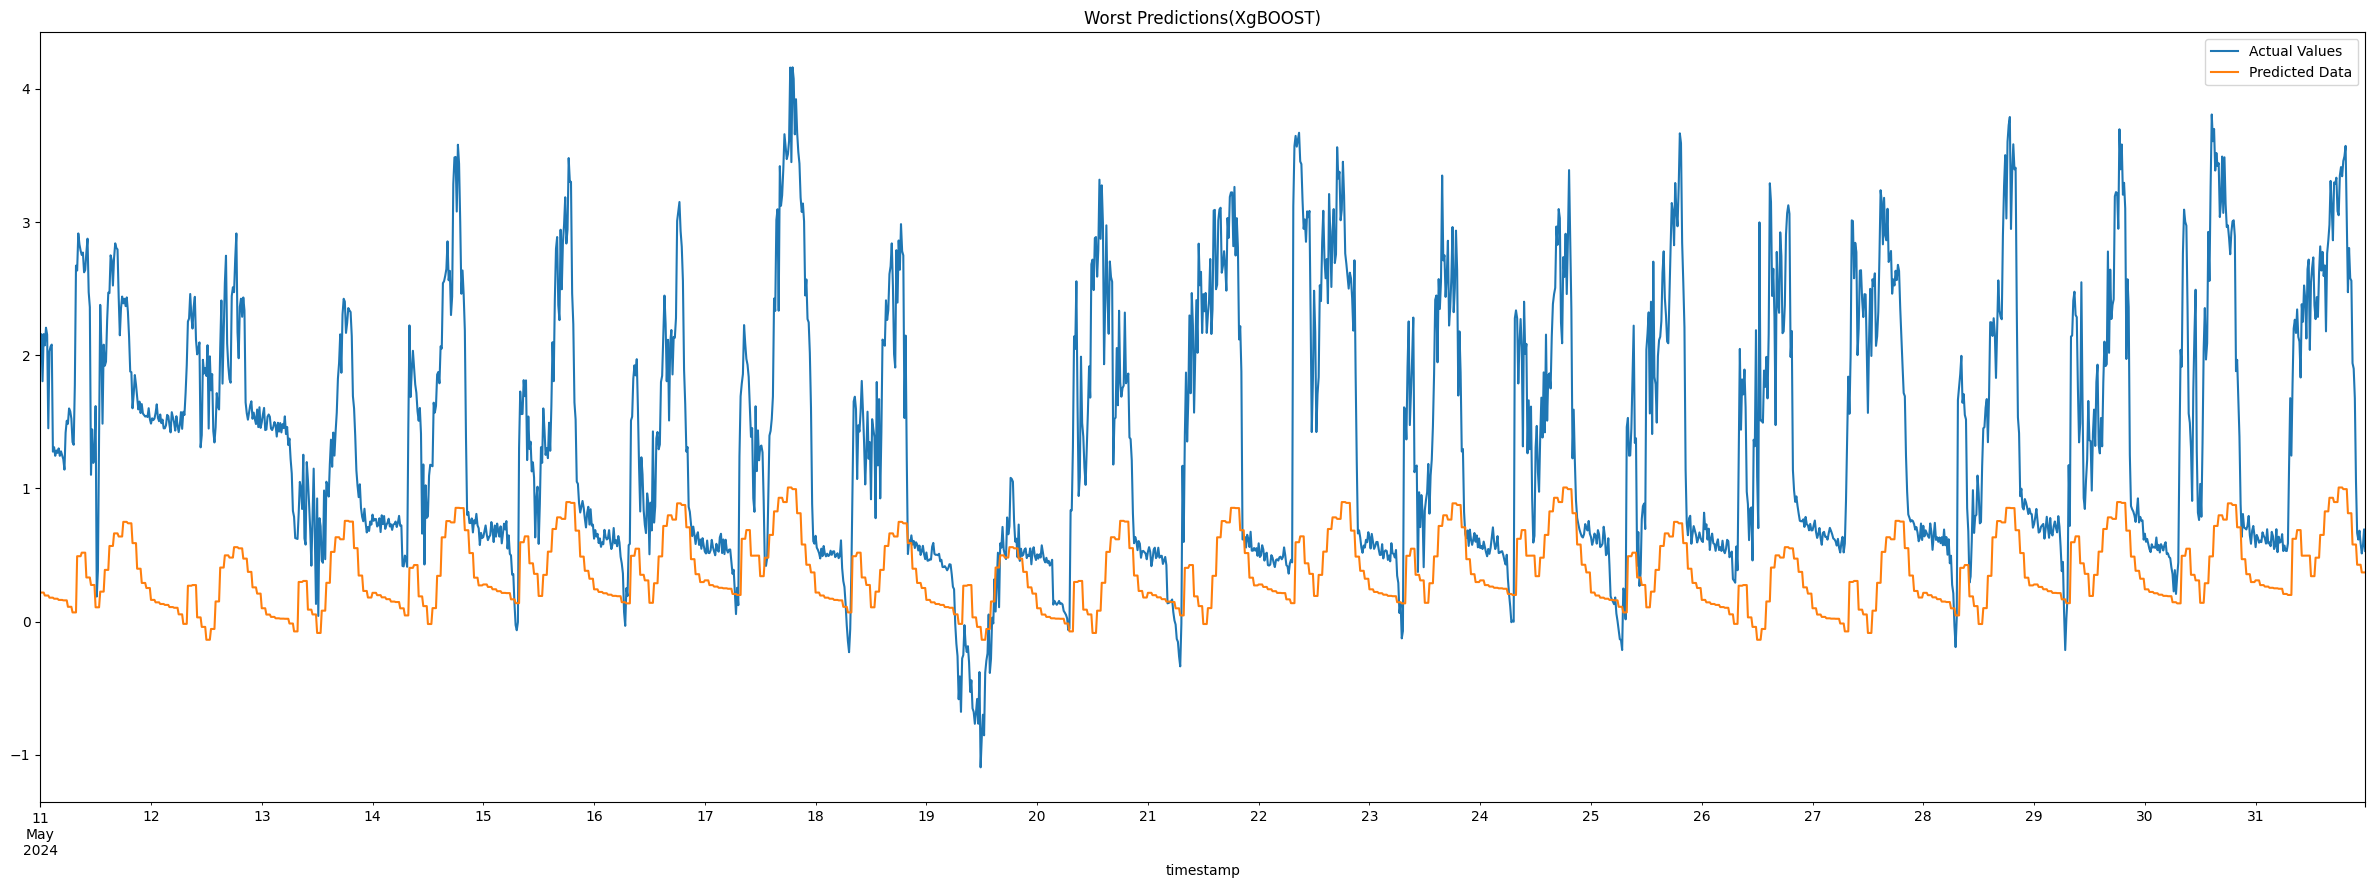

In [ ]:
plt.figure(figsize=(20, 10))  # Set the size of the figure here

ax = y_test['2024-05-11':'2024-05-31'].plot(figsize=(30,10))
test['predictions']['2024-05-11':'2024-05-31'].plot(ax=ax)
plt.legend(['Actual Values', 'Predicted Data'])
plt.title("Worst Predictions(XgBOOST)")
plt.show()

<Figure size 2000x1000 with 0 Axes>

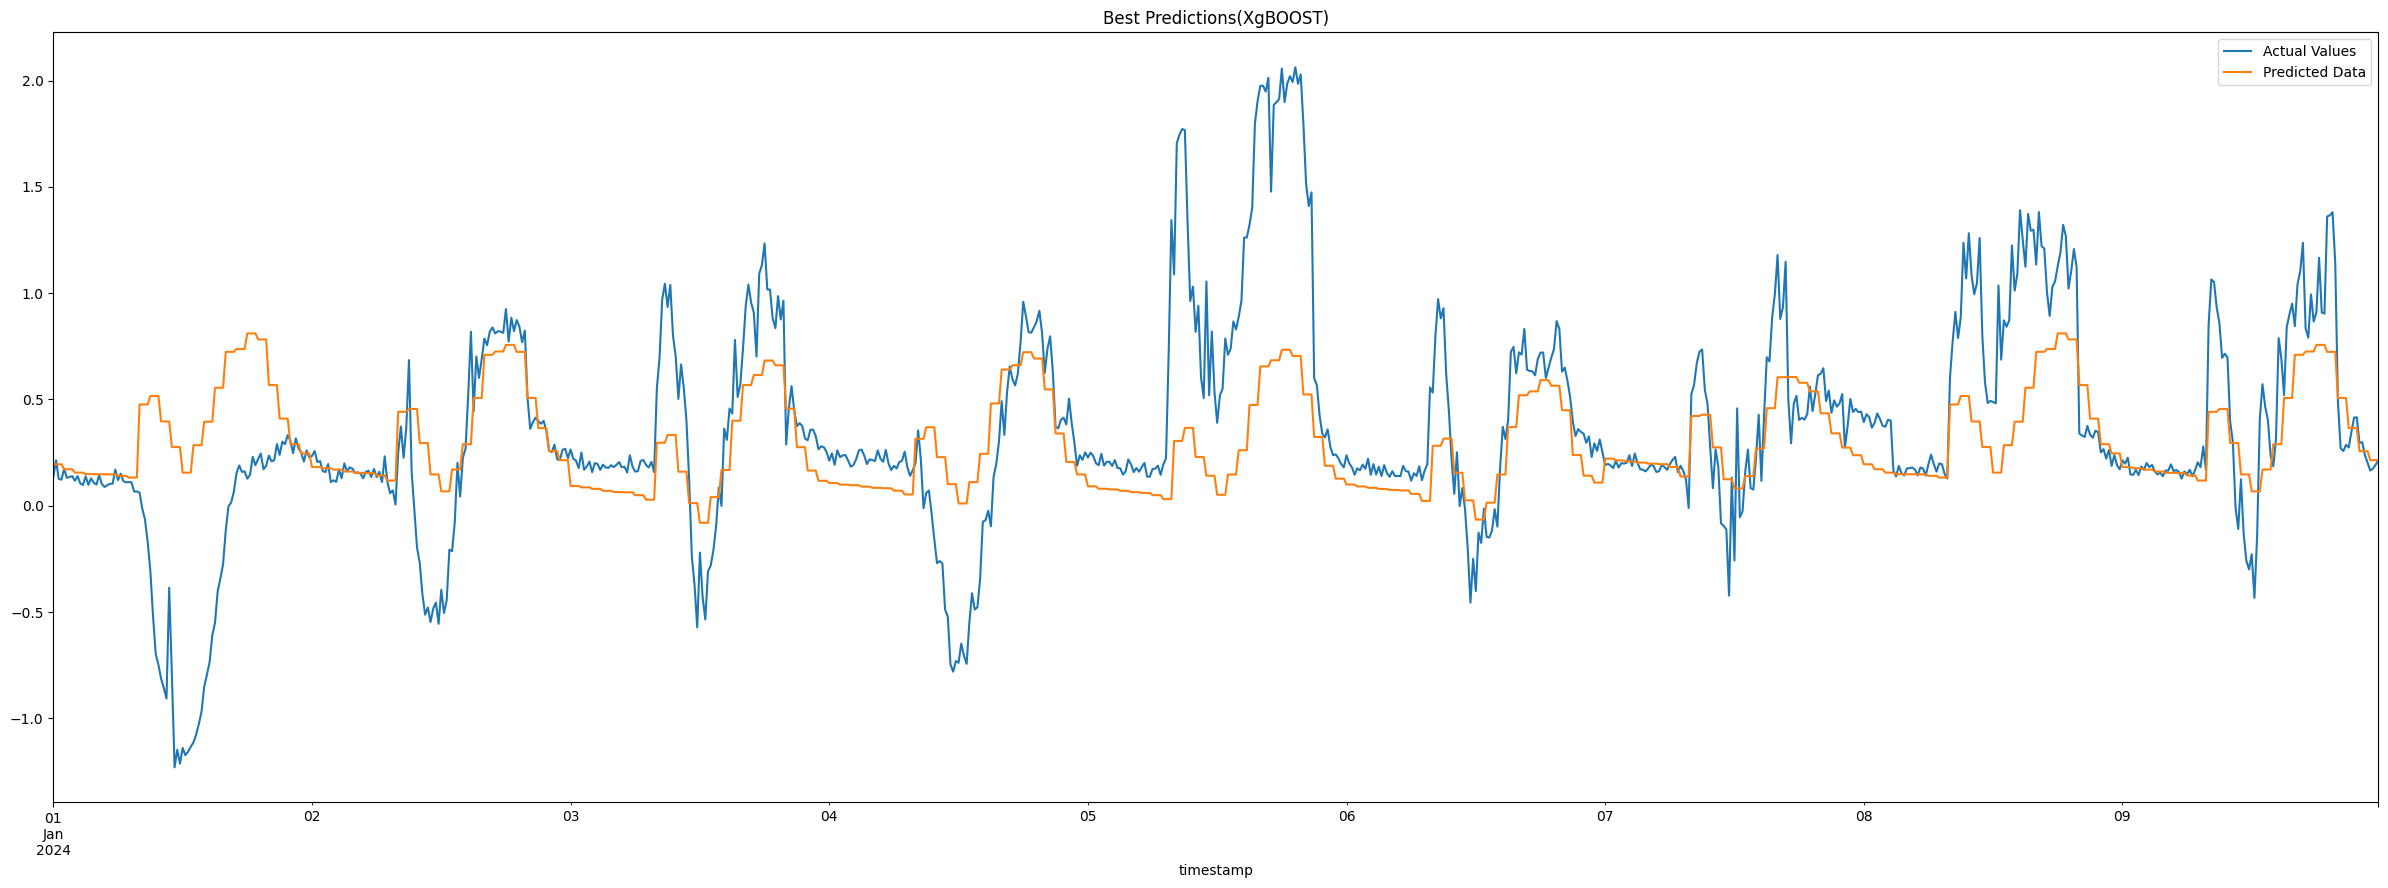

In [ ]:
plt.figure(figsize=(20, 10))  # Set the size of the figure here

ax = y_test['2024-01-01':'2024-01-09'].plot(figsize=(30,10))
test['predictions']['2024-01-01':'2024-01-09'].plot(ax=ax)
plt.legend(['Actual Values', 'Predicted Data'])
plt.title("Best Predictions(XgBOOST)")
plt.show()